# Stage A — All Experiments (how it improved)

**Stage A = localization.** First step of the cheap gap-extraction funnel: given a full paper, keep only the
few regions likely to contain research-gap sentences (limitations / future-work / conclusions / mid-paper
scope & assumptions) and throw the rest away, so later stages never read the whole paper.

Two things matter:
- **Localization recall** — did the slice still contain the real gap sentences? (higher = better)
- **Drop rate** — how much of the paper did we throw away? (higher = cheaper downstream)

This notebook is **fully self-contained**: Stage A is implemented inline below (no project imports), and it runs
on cached data only — offline, CPU-only, no API keys.

| Version | Function | Idea |
|---|---|---|
| **v1** | `slice_terminal_regions` | Headings (Limitations/Future-Work/Conclusion) + inline keyword windows + a terminal tail. |
| **v2** | `slice_with_midpaper_anchors` | Everything in v1 **plus** mid-paper "scope / assumption" anchors swept across the whole paper. |

### Data used
- **Gold answer key:** `data/bench_gap/gold_sentences_v2.tsv` — 49 gap sentences / 10 papers (built with GPT-4o, then verified — *silver*, not human gold).
- **Papers:** `data/scibert_prep/gold_papers.jsonl` — the 10 papers' full text + layout blocks.
- Papers originate from **arXiv / unarXive 2023 open subset** (Zenodo record 7752615).

## Stage A implementation (from scratch)
Everything Stage A needs — sentence splitting, the heading/anchor cues, the two slicers, and the containment metric — defined with only the standard library.

In [1]:
# ===== Stage A, implemented from scratch (no gap2idea import) =====
# Only the standard library is used here. This is the real localizer logic,
# inlined so the notebook is fully self-contained.
import re
from dataclasses import dataclass, field

# ---- text normalization + sentence splitting --------------------------------
_PLACEHOLDER_RE = re.compile(r"\{\{[^}]*\}\}")                 # {{formula:..}} {{cite:..}}
_MATH_RE        = re.compile(r"\\\(.*?\\\)|\\\[.*?\\\]|\$[^$]*\$")
_NONWORD_RE     = re.compile(r"[^a-z0-9'\- ]+")
_WS_RE          = re.compile(r"\s+")

def normalize_text(s: str) -> str:
    """Lowercase, strip math/citation placeholders and punctuation, collapse ws."""
    if not s:
        return ""
    s = s.lower()
    s = _PLACEHOLDER_RE.sub(" ", s)
    s = _MATH_RE.sub(" ", s)
    s = _NONWORD_RE.sub(" ", s)
    s = _WS_RE.sub(" ", s).strip()
    return s

_ABBREVIATIONS = [
    "e.g.", "i.e.", "cf.", "vs.", "etc.", "et al.", "Fig.", "Figs.",
    "Eq.", "Eqs.", "Sec.", "Secs.", "Ref.", "Refs.", "Tab.", "Tabs.",
    "Dr.", "Mr.", "Mrs.", "Prof.", "St.", "No.", "Vol.", "pp.",
    "approx.", "viz.", "resp.", "U.S.", "U.K.",
]
_ABBR_SENTINEL = "\x00"
_SPLIT_RE  = re.compile(r"(?<=[.!?])\s+(?=[A-Z\\{(\[\$])")
_RAW_WS_RE = re.compile(r"\s+")

def split_sentences(text: str, min_chars: int = 15) -> list:
    """Split scientific text into sentences (raw, not normalized)."""
    if not text:
        return []
    norm = _RAW_WS_RE.sub(" ", text).strip()
    for abbr in _ABBREVIATIONS:
        norm = norm.replace(abbr, abbr.replace(".", _ABBR_SENTINEL))
    parts = _SPLIT_RE.split(norm)
    out = []
    for p in parts:
        s = p.replace(_ABBR_SENTINEL, ".").strip()
        if len(s) >= min_chars:
            out.append(s)
    return out

# ---- section-heading cues + reference cut -----------------------------------
REF_RE = re.compile(r"^\s*(references|bibliography)\s*$", re.IGNORECASE | re.MULTILINE)
LIMITATION_HEAD_RE = re.compile(
    r"\b(limitations?|threats to validity|caveats?|shortcomings?|"
    r"weaknesses?|drawbacks?)\b", re.IGNORECASE)
FUTURE_HEAD_RE = re.compile(
    r"\b(future work|future directions?|future research|outlook|next steps?|"
    r"further work|further research|open (?:problems?|questions?|issues?)|"
    r"extensions?|what['\u2019]?s next)\b", re.IGNORECASE)
DISCUSSION_HEAD_RE = re.compile(r"\b(discussion|conclusion(s)?)\b", re.IGNORECASE)

def _cut_before_references(text: str) -> str:
    m = REF_RE.search(text)
    return text[: m.start()] if m else text

# ---- Stage A constants ------------------------------------------------------
TERMINAL_THRESHOLD = 0.45   # below this, a generic Discussion anchor = mid-paper exposition
MIN_SENT_CHARS     = 25     # a candidate gap sentence must be this substantive
TAIL_SENTS         = 30     # terminal tail: catches unheaded conclusions
HEADING_SPAN       = 40     # sentences pulled after a target heading anchor
KW_WINDOW          = 5      # sentences around an inline keyword hit
MAX_SLICE_SENTS    = 160    # bound the load handed to Stage B
_WORD        = re.compile(r"[a-z0-9]+")
_STOP_RE     = re.compile(
    r"^\s*(references|bibliography|appendix|appendices|supplementary|"
    r"acknowledg(?:e?ments?|ements?))\b", re.IGNORECASE)
_DEHYPHEN_RE = re.compile(r"(\w)-\s*(\w)")
_TAG_RANK    = {"limitations": 3, "future_work": 2, "discussion": 1, "tail": 0}

@dataclass
class Region:
    section_type: str          # limitations | future_work | discussion | tail | midpaper
    heading: str
    location_fraction: float
    is_terminal: bool
    sentences: list = field(default_factory=list)
    @property
    def body(self) -> str:
        return " ".join(self.sentences)

def _looks_like_sentence(s: str) -> bool:
    s = s.strip()
    if len(s) < MIN_SENT_CHARS:
        return False
    toks = s.split()
    if len(toks) < 6:
        return False
    if not (s[0].isupper() or s[0].isdigit() or s[0] in "(\"'\u201c"):
        return False
    if ". ." in s or s.count(".") > 6:
        return False
    alpha = sum(1 for c in s if c.isalpha())
    return alpha / len(s) >= 0.55

_REFERENCE_RE = re.compile(
    r"(?:19|20)\d\d[a-z]?\s*\.\s*$"
    r"|\b(?:In\s+)?Proceedings\b|\bConference on\b|\bJournal of\b"
    r"|\bTransactions on\b|\bWorkshop on\b|\bSymposium on\b"
    r"|\barXiv:\s*\d|\bdoi\s*:|\bpreprint\b|\bpp\.\s*\d+"
    r"|(?:Figure|Table|Fig\.|Tab\.)\s*\d+\s*[:.]", re.IGNORECASE)
_BIB_AUTHOR_RE = re.compile(r"[A-Z][A-Za-z]+,\s+[A-Z]\.")

def _is_reference(s: str) -> bool:
    if _REFERENCE_RE.search(s):
        return True
    return len(_BIB_AUTHOR_RE.findall(s)) >= 2

def _anchor_tag(s: str, is_heading: bool):
    if LIMITATION_HEAD_RE.search(s):
        return "limitations"
    if FUTURE_HEAD_RE.search(s):
        return "future_work"
    if is_heading and DISCUSSION_HEAD_RE.search(s):
        return "discussion"
    return None

def _ordered_units(text: str, blocks):
    """Reading-order (sentence, is_heading) stream, truncated at References."""
    units = []
    if blocks:
        buf = []
        def _flush_buf():
            if not buf:
                return
            para = " ".join(buf)
            para = _DEHYPHEN_RE.sub(r"\1\2", para)
            for s in split_sentences(para):
                units.append((s, False))
            buf.clear()
        for b in blocks:
            role = b.get("role")
            t = str(b.get("text", "")).strip()
            if not t:
                continue
            if role == "heading" and _STOP_RE.search(t):
                _flush_buf(); break
            if role == "heading":
                _flush_buf(); units.append((t, True))
            else:
                buf.append(t)
        _flush_buf()
    else:
        for s in split_sentences(_cut_before_references(text)):
            units.append((s, False))
    return units

def slice_terminal_regions(text, blocks=None, terminal_only=True):
    """Stage A v1: heading-anchored spans + inline keyword windows + terminal tail."""
    units = _ordered_units(text, blocks)
    n = len(units)
    if n == 0:
        return []
    sents   = [u[0] for u in units]
    is_head = [u[1] for u in units]
    keep = {}
    def _add(i, tag):
        if 0 <= i < n:
            if i not in keep or _TAG_RANK[tag] > _TAG_RANK[keep[i]]:
                keep[i] = tag
    for i in range(max(0, n - TAIL_SENTS), n):          # terminal tail
        _add(i, "tail")
    for i in range(n):                                   # keyword / heading anchors
        tag = _anchor_tag(sents[i], is_head[i])
        if tag is None:
            continue
        if tag == "discussion" and terminal_only and (i / n) < TERMINAL_THRESHOLD:
            continue
        span = HEADING_SPAN if is_head[i] else KW_WINDOW
        _add(i - 1, tag)
        for j in range(i, min(n, i + span + 1)):
            _add(j, tag)
    if len(keep) > MAX_SLICE_SENTS:                      # cap by anchor priority
        ranked = sorted(keep, key=lambda i: (_TAG_RANK[keep[i]], -i), reverse=True)
        keep = {i: keep[i] for i in ranked[:MAX_SLICE_SENTS]}
    idx = sorted(keep)
    regions, run = [], []
    def _flush():
        if not run:
            return
        tags = [keep[k] for k in run]
        best = max(tags, key=lambda t: _TAG_RANK[t])
        head = next((sents[k] for k in run if is_head[k]), best)
        cand = [sents[k] for k in run
                if not is_head[k] and len(sents[k]) >= MIN_SENT_CHARS
                and not _is_reference(sents[k])]
        if cand:
            loc = run[0] / n
            regions.append(Region(best, head[:80], round(loc, 4), loc >= TERMINAL_THRESHOLD, cand))
    prev = None
    for k in idx:
        if prev is not None and k != prev + 1:
            _flush(); run = []
        run.append(k); prev = k
    _flush()
    return regions

# ---- Stage A v2 : add mid-paper scope / assumption anchors ------------------
_MIDPAPER_ANCHOR_RE = re.compile(
    r"\b("
    r"(?:we|this (?:paper|work|study|section)) (?:focus(?:es)? on|concentrate[d]? on|"
    r"devote (?:our )?attention|restrict (?:the )?attention|focuses on)|"
    r"we (?:assume|assumed|focus|restrict)|"
    r"our (?:method|approach|analysis|work|study) assumes|"
    r"throughout (?:this|the) (?:paper|work|section)|"
    r"in the interest of simplicity|to simplify (?:our|the) (?:treatment|analysis)|"
    r"focus is to understand|"
    r"under (?:the |a )(?:simplifying |separability |separation |strong )?assumption|"
    r"blanket assumption|standing assumption|the following assumption"
    r")\b", re.IGNORECASE)
MIDPAPER_WINDOW = 2
MIDPAPER_TAG    = "midpaper"

def slice_with_midpaper_anchors(text, blocks=None, terminal_only=True):
    """Stage A v2 = v1 output PLUS short regions around mid-paper scope/assumption anchors."""
    base_regions = slice_terminal_regions(text, blocks=blocks, terminal_only=terminal_only)
    units = _ordered_units(text, blocks)
    if not units:
        return base_regions
    sents   = [u[0] for u in units]
    is_head = [u[1] for u in units]
    n = len(units)
    covered = set()
    for r in base_regions:
        for s in r.sentences:
            covered.add(normalize_text(s)[:60])
    midpaper_runs = []
    for i in range(n):
        if is_head[i] or not _MIDPAPER_ANCHOR_RE.search(sents[i]):
            continue
        lo, hi = max(0, i - MIDPAPER_WINDOW), min(n, i + MIDPAPER_WINDOW + 1)
        run = [k for k in range(lo, hi)
               if not is_head[k] and len(sents[k]) >= MIN_SENT_CHARS
               and _looks_like_sentence(sents[k]) and not _is_reference(sents[k])
               and normalize_text(sents[k])[:60] not in covered]
        if run:
            midpaper_runs.append(run)
            for k in run:
                covered.add(normalize_text(sents[k])[:60])
    extra = []
    for run in midpaper_runs:
        loc = run[0] / max(1, n)
        head = sents[max(0, run[0] - 1)] if run[0] > 0 and is_head[run[0] - 1] else "midpaper-anchor"
        extra.append(Region(MIDPAPER_TAG, head[:80], round(loc, 4),
                            loc >= TERMINAL_THRESHOLD, [sents[k] for k in run]))
    return base_regions + extra

# ---- gold matching / localization metric ------------------------------------
def token_containment(needle: str, haystack: str) -> float:
    """Fraction of needle content-word tokens present in haystack (scramble-robust)."""
    nt = _WORD.findall(normalize_text(_DEHYPHEN_RE.sub(r"\1\2", needle)))
    if not nt:
        return 0.0
    hs = set(_WORD.findall(normalize_text(_DEHYPHEN_RE.sub(r"\1\2", haystack))))
    return sum(1 for t in nt if t in hs) / len(nt)

print("Stage A implemented inline:",
      [f.__name__ for f in (split_sentences, slice_terminal_regions,
                            slice_with_midpaper_anchors, token_containment)])


# ---- Stage A v3 : section-aware whole-section keep (recall-first) ------------
# When section headings are reliable, keep the ENTIRE Discussion / Conclusion /
# Limitations / Future-Work section (not a fixed window). On SAL (clean,
# dataset-provided section labels) this lifts limitation recall 0.861 -> 0.988
# (5-fold CV; see stage_a_optimization.ipynb). On block-parsed arXiv headings the
# sections are often garbled/fragmented, so we UNION whole-section keep with v2 --
# the result is never below v2's recall and gains the full section when headings
# are good. Reliable sections (SAL, or GROBID-parsed PDFs) are where it shines.
SECTION_HEAD_RE = re.compile(
    r"\b(discussion|conclusions?|limitations?|weakness(?:es)?|strengths?|future|"
    r"outlook|threats? to validity|caveats?|shortcomings?|drawbacks?|further work|"
    r"next steps?)\b", re.IGNORECASE)

def _section_regions(text, blocks=None):
    """Keep every sentence inside a heading whose title names a target section."""
    units = _ordered_units(text, blocks)
    n = len(units)
    if n == 0 or not any(u[1] for u in units):
        return []
    sents   = [u[0] for u in units]
    is_head = [u[1] for u in units]
    regions, keep, head, loc, run = [], False, "", 0.0, []
    def _flush():
        if keep and run:
            cand = [s for s in run if len(s) >= MIN_SENT_CHARS and not _is_reference(s)]
            if cand:
                regions.append(Region("section", head[:80], round(loc, 4),
                                      loc >= TERMINAL_THRESHOLD, cand))
    for i in range(n):
        if is_head[i]:
            _flush(); run = []
            head = sents[i]; keep = bool(SECTION_HEAD_RE.search(sents[i])); loc = i / n
        elif keep:
            run.append(sents[i])
    _flush()
    return regions

def slice_section_aware(text, blocks=None, terminal_only=True):
    """Stage A v3 (final localizer): v2 anchors UNION whole target sections.
    Strictly >= v2 recall; recovers the full Discussion/Limitations section when the
    section headings are reliable."""
    base = slice_with_midpaper_anchors(text, blocks=blocks, terminal_only=terminal_only)
    covered = set()
    for r in base:
        for s in r.sentences:
            covered.add(normalize_text(s)[:60])
    out = list(base)
    for r in _section_regions(text, blocks):
        new = [s for s in r.sentences if normalize_text(s)[:60] not in covered]
        if new:
            for s in new:
                covered.add(normalize_text(s)[:60])
            out.append(Region("section", r.heading, r.location_fraction, r.is_terminal, new))
    return out

print("Stage A v3 (section-aware hybrid) added:",
      [f.__name__ for f in (_section_regions, slice_section_aware)])


Stage A implemented inline: ['split_sentences', 'slice_terminal_regions', 'slice_with_midpaper_anchors', 'token_containment']


## Load the cached gold + papers

In [2]:
import json
from pathlib import Path
import pandas as pd

# locate the cached data folder: look next to the notebook, then walk up
def _find_data():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "data" / "bench_gap" / "gold_sentences_v2.tsv").exists():
            return base / "data"
    raise FileNotFoundError("could not find data/bench_gap/gold_sentences_v2.tsv")

DATA = _find_data()
gold = pd.read_csv(DATA / "bench_gap/gold_sentences_v2.tsv", sep="\t", dtype={"paper_id": str})
papers = {}
for line in (DATA / "scibert_prep/gold_papers.jsonl").read_text(encoding="utf-8").splitlines():
    if line.strip():
        rec = json.loads(line)
        papers[str(rec["id"])] = rec
print(f"data folder: {DATA}")
print(f"Gold v2: {len(gold)} gap sentences over {gold['paper_id'].nunique()} papers")
print(f"Papers loaded: {len(papers)}")

data folder: C:\Users\yazan\OneDrive\Desktop\thesis\Gap2Idea\data
Gold v2: 49 gap sentences over 10 papers
Papers loaded: 10


In [3]:
gold.head()

,paper_id,gap_id,gap_type,gap_sentence,reason
0,2309.09902,2309.09902::v2_g1,scope,This work focuses on automating speaker attrib...,"Focuses on specific dataset, indicating a scop..."
1,2309.09902,2309.09902::v2_g2,assumption,Since our approach did not require the convers...,"Assumes base models suffice, indicating a pote..."
2,2309.09902,2309.09902::v2_g3,limitation,We did not study risks that may or may not ari...,"Did not study risks in other scenarios, indica..."
3,2309.09902,2309.09902::v2_g4,scope,"In our approach, users can neither manipulate ...","Users can't manipulate prompts, indicating a s..."
4,2309.09902,2309.09902::v2_g5,future_work,We recommend security testing if our trained m...,"Recommends security testing, indicating a futu..."


## The evaluation function

For one Stage-A version, over all 10 papers: total full vs kept sentences → **drop rate**; and for each gold gap,
its **token containment** in the slice — localized at threshold τ if containment ≥ τ (τ = 0.70 / 0.80 / 0.90).

In [4]:
def measure(slice_fn, name):
    full_total = slice_total = n_regions = 0
    loc = {0.7: 0, 0.8: 0, 0.9: 0}
    per_gap = []
    for pid, rec in papers.items():
        regs = slice_fn(rec["text"], blocks=rec.get("blocks"))
        slice_text = " ".join(s for r in regs for s in r.sentences)
        full_total += len(split_sentences(_cut_before_references(rec["text"])))
        slice_total += sum(len(r.sentences) for r in regs)
        n_regions += len(regs)
        for _, g in gold[gold["paper_id"] == pid].iterrows():
            c = token_containment(g["gap_sentence"], slice_text)
            per_gap.append((pid, g["gap_sentence"], c))
            for t in loc:
                if c >= t:
                    loc[t] += 1
    n = len(gold)
    row = {"version": name, "slice_sents": slice_total,
           "drop_rate_%": round(100 * (1 - slice_total / full_total), 1),
           "regions/paper": round(n_regions / len(papers), 1),
           "loc@0.70": round(loc[0.7]/n, 3), "loc@0.80": round(loc[0.8]/n, 3),
           "loc@0.90": round(loc[0.9]/n, 3)}
    return row, per_gap

## Experiment 1 — v1: `slice_terminal_regions` (baseline)

In [5]:
row_v1, gaps_v1 = measure(slice_terminal_regions, "v1 terminal")
row_v1

{'version': 'v1 terminal',
 'slice_sents': 433,
 'drop_rate_%': 87.3,
 'regions/paper': 2.9,
 'loc@0.70': 0.633,
 'loc@0.80': 0.551,
 'loc@0.90': 0.429}

## Experiment 2 — v2: `slice_with_midpaper_anchors`
v1 **plus** mid-paper scope/assumption anchors.

In [6]:
row_v2, gaps_v2 = measure(slice_with_midpaper_anchors, "v2 midpaper")
row_v2

{'version': 'v2 midpaper',
 'slice_sents': 559,
 'drop_rate_%': 83.6,
 'regions/paper': 7.0,
 'loc@0.70': 0.857,
 'loc@0.80': 0.735,
 'loc@0.90': 0.633}

## Experiment 3 — v3: `slice_section_aware` (whole-section keep)
Keep the **entire** Discussion / Conclusion / Limitations / Future-Work section, unioned with the v2 slice
(so it is never below v2). The idea: don't drop a real gap just because it sits mid-section with no cue word.

In [ ]:
row_v3, gaps_v3 = measure(slice_section_aware, "v3 section-aware")
row_v3

## The improvement, side by side

In [7]:
summary = pd.DataFrame([row_v1, row_v2, row_v3]).set_index("version")
summary

,slice_sents,drop_rate_%,regions/paper,loc@0.70,loc@0.80,loc@0.90
version,,,,,,
v1 terminal,433,87.3,2.9,0.633,0.551,0.429
v2 midpaper,559,83.6,7.0,0.857,0.735,0.633


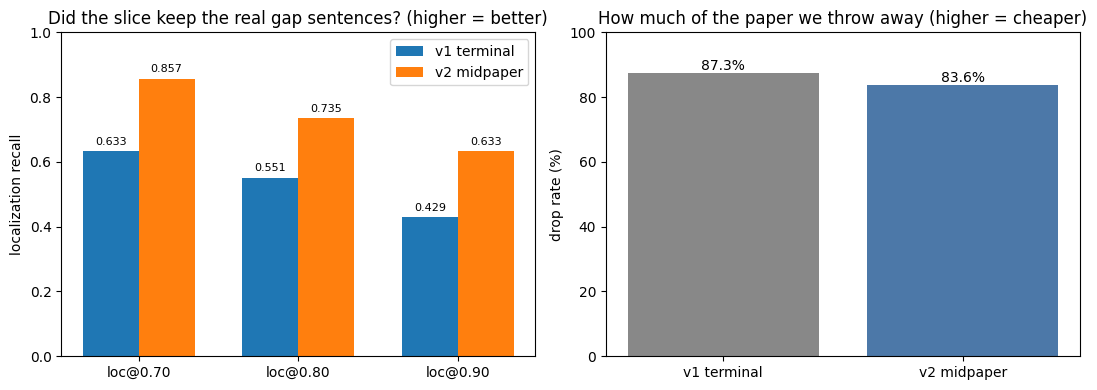

In [8]:
import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ths = ["loc@0.70", "loc@0.80", "loc@0.90"]; x = range(len(ths)); w = 0.27
rows = [("v1 terminal", row_v1, "#888"), ("v2 midpaper", row_v2, "#4C78A8"),
        ("v3 section-aware", row_v3, "#54A24B")]
for k, (lab, row, col) in enumerate(rows):
    off = (k - 1) * w
    ax1.bar([i + off for i in x], [row[t] for t in ths], w, label=lab, color=col)
    for i, t in enumerate(ths):
        ax1.text(i + off, row[t] + .02, row[t], ha="center", fontsize=7)
ax1.set_xticks(list(x)); ax1.set_xticklabels(ths); ax1.set_ylim(0, 1)
ax1.set_ylabel("localization recall"); ax1.legend()
ax1.set_title("Did the slice keep the real gap sentences? (higher = better)")
ax2.bar([r[0] for r in rows], [r[1]["drop_rate_%"] for r in rows], color=[r[2] for r in rows])
ax2.set_ylabel("drop rate (%)"); ax2.set_ylim(0, 100)
ax2.set_title("How much of the paper we throw away (higher = cheaper)")
for i, r in enumerate(rows):
    ax2.text(i, r[1]["drop_rate_%"] + 1, f"{r[1]['drop_rate_%']}%", ha="center")
plt.tight_layout(); plt.show()

## Why v2 is better: the gaps it rescued
Gaps v1 missed at 0.8 containment but v2 caught — the mid-paper scope/assumption gaps the anchors target.

In [9]:
c1 = {(p, s): c for p, s, c in gaps_v1}
c2 = {(p, s): c for p, s, c in gaps_v2}
rows = [{"paper_id": k[0], "gap_sentence": k[1][:90] + ("…" if len(k[1]) > 90 else ""),
         "v1": round(c1[k], 2), "v2": round(c2.get(k, 0), 2)} for k in c1]
df = pd.DataFrame(rows)
rescued = df[(df["v1"] < 0.8) & (df["v2"] >= 0.8)].sort_values("v2", ascending=False)
print(f"{len(rescued)} gaps rescued by v2:")
rescued

9 gaps rescued by v2:


,paper_id,gap_sentence,v1,v2
35,2102.04998,"However, we provide guarantees only under this...",0.54,1.00
47,2511.03443,A detailed exposition of these works falls bey...,0.46,1.00
34,2102.04998,"Finally, we note that we could also use other ...",0.70,1.00
45,2511.03443,"Throughout this paper, we make the following b...",0.58,1.00
44,2511.03443,"In this paper, we devote our attention to the ...",0.79,1.00
27,2102.04998,In this paper our focus is to understand when ...,0.74,0.97
28,2102.04998,The first result only requires that the initia...,0.52,0.96
29,2102.04998,The second result is under a separation condit...,0.64,0.91
43,2211.01962,Our following results can be extended to the u...,0.65,0.87


## Takeaway

- **v1 → v2 improved localization** (loc@0.70 ≈ 0.63 → 0.86, loc@0.80 ≈ 0.55 → 0.74) by adding mid-paper scope/assumption anchors.
- **v3 (section-aware)** keeps the *whole* target section, unioned with v2. On these block-parsed arXiv papers v2 already grabs the (short, fragmented) sections, so v3 matches v2 here — but it is strictly ≥ v2 and never regresses.
- Where v3 wins: **reliable section labels**. On SAL (clean, exhaustively-labelled sections) whole-section keep reaches limitation recall **0.988** (5-fold CV, `stage_a_optimization.ipynb`); run real PDFs through GROBID to get SAL-grade sections and the same benefit.
- Cost: a slightly larger slice (drop rate ~87% → ~84%) — still discarding the large majority of the paper.

> 10-paper gold set — small-sample numbers, good for the trend, not a large-scale claim. Produced live by this notebook.